# Statistics and Probability for Machine Learning

Machine learning is applied statistics at scale. This notebook builds the statistical intuition needed
to evaluate models and experiments:

- populations, samples, and sampling distributions,
- the central limit theorem and standard error,
- confidence intervals and coverage,
- hypothesis tests, p-values, and Type I/II errors,
- effect size and statistical power,
- A/B testing,
- bootstrap intervals,
- correlation, causation, and multiple comparisons.

## Learning objectives

1. Explain why sample estimates vary and how standard error quantifies that uncertainty.
2. Construct and interpret confidence intervals.
3. Interpret p-values correctly and avoid common misinterpretations.
4. Run a two-proportion A/B test and compute an effect size.
5. Use bootstrap resampling for uncertainty estimates.
6. Recognise when correlation does not imply causation.

## 1. Populations and samples

A **population** is the full set of units we care about. A **sample** is the subset we observe.
Statistics computed on a sample vary from sample to sample. The distribution of a statistic across
repeated samples is its **sampling distribution**.

The **standard error** of the sample mean is:

$$SE = \frac{\sigma}{\sqrt{n}}$$

It shrinks with the square root of the sample size.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. The central limit theorem

Even when the population is skewed, the distribution of the sample mean becomes approximately normal
as the sample size grows. We simulate an exponential population and draw many samples.

Population mean: 9.991
Population std: 10.014


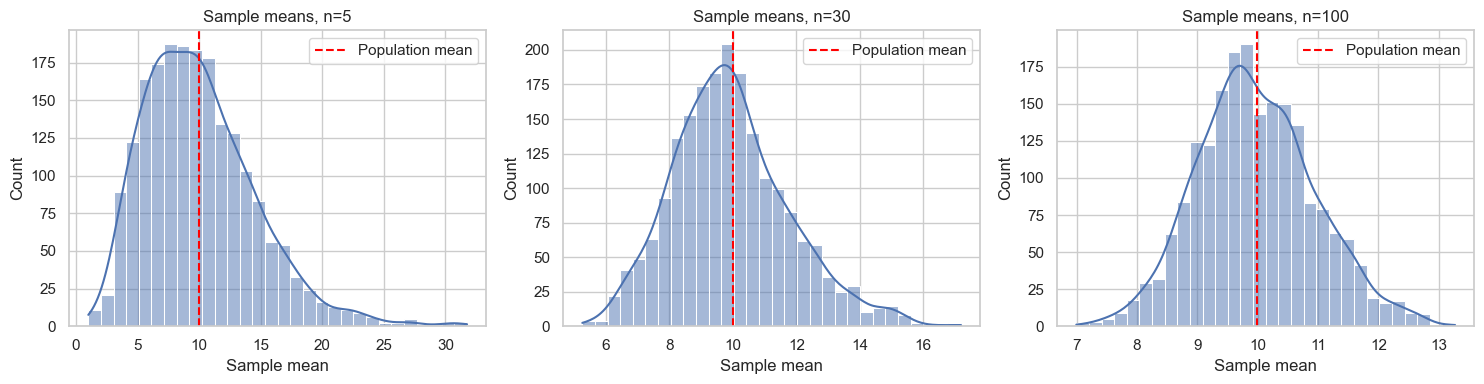

In [2]:
population = rng.exponential(scale=10.0, size=200_000)
print("Population mean:", round(population.mean(), 3))
print("Population std:", round(population.std(), 3))

sample_sizes = [5, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n in zip(axes, sample_sizes):
    means = [rng.choice(population, size=n, replace=False).mean() for _ in range(2000)]
    sns.histplot(means, bins=30, kde=True, ax=ax)
    ax.axvline(population.mean(), color="red", linestyle="--", label="Population mean")
    ax.set_title(f"Sample means, n={n}")
    ax.set_xlabel("Sample mean")
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Standard error and confidence intervals

A 95% confidence interval for the mean is:

$$\bar{x} \pm t_{0.975, n-1}\frac{s}{\sqrt{n}}$$

The correct interpretation is about the procedure: if we repeated the experiment many times, about
95% of the intervals would contain the true mean. It is not "the probability that the true mean is in
this interval".

In [3]:
sample = rng.choice(population, size=80, replace=False)
n = len(sample)
mean = sample.mean()
se = stats.sem(sample)
ci_low, ci_high = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)

print(f"Sample mean: {mean:.3f}")
print(f"Standard error: {se:.3f}")
print(f"95% CI: ({ci_low:.3f}, {ci_high:.3f})")

Sample mean: 9.416
Standard error: 1.164
95% CI: (7.099, 11.733)


### Coverage simulation

We simulate many experiments and check how often the interval contains the known population mean.

In [4]:
coverage = 0
trials = 1000
for _ in range(trials):
    sample = rng.choice(population, size=80, replace=False)
    low, high = stats.t.interval(
        0.95, df=len(sample) - 1, loc=sample.mean(), scale=stats.sem(sample)
    )
    coverage += int(low <= population.mean() <= high)

print("Coverage of the 95% CI:", coverage / trials)

Coverage of the 95% CI: 0.932


## 5. Hypothesis testing

A hypothesis test compares a null hypothesis $H_0$ with an alternative $H_1$.

- **p-value**: probability of observing a result at least as extreme as ours, assuming $H_0$ is true.
- It is **not** the probability that $H_0$ is true.
- A small p-value is evidence against $H_0$, not proof that $H_1$ is true.
- **Type I error**: rejecting a true null (false positive).
- **Type II error**: failing to reject a false null (false negative).
- **Power**: probability of rejecting a false null.

We compare two groups with a Welch t-test.

In [5]:
group_a = rng.normal(loc=50, scale=10, size=200)
group_b = rng.normal(loc=53, scale=10, size=200)

t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False)
print(f"t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.4f}")

pooled_std = np.sqrt((group_a.var(ddof=1) + group_b.var(ddof=1)) / 2)
cohens_d = (group_b.mean() - group_a.mean()) / pooled_std
print(f"Cohen's d: {cohens_d:.3f}")

t-statistic: -3.864
p-value: 0.0001
Cohen's d: 0.386


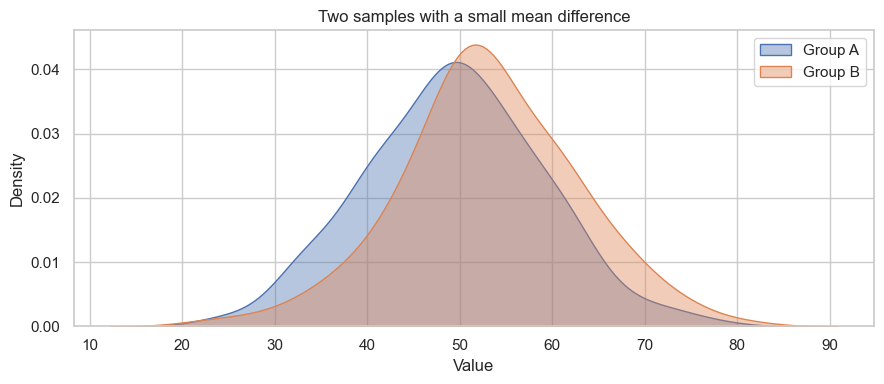

In [6]:
plt.figure(figsize=(9, 4))
sns.kdeplot(group_a, fill=True, label="Group A", alpha=0.4)
sns.kdeplot(group_b, fill=True, label="Group B", alpha=0.4)
plt.title("Two samples with a small mean difference")
plt.xlabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

### Type I error simulation

If the null hypothesis is true and we test at $\alpha = 0.05$, about 5% of experiments should reject
the null. We verify this by simulation.

In [7]:
false_positives = 0
trials = 2000
for _ in range(trials):
    a = rng.normal(0, 1, 100)
    b = rng.normal(0, 1, 100)
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    false_positives += int(p < 0.05)

print("False-positive rate:", false_positives / trials)

False-positive rate: 0.0505


## 6. A/B testing with conversion rates

For a binary outcome, compare conversion counts with a two-proportion z-test and report confidence
intervals for each rate and the absolute lift.

In [8]:
visitors_a, conversions_a = 5000, 250
visitors_b, conversions_b = 5000, 285

counts = np.array([conversions_a, conversions_b])
totals = np.array([visitors_a, visitors_b])

z_stat, p_value = proportions_ztest(counts, totals, alternative="two-sided")
ci_a = proportion_confint(conversions_a, visitors_a, method="wilson")
ci_b = proportion_confint(conversions_b, visitors_b, method="wilson")

rate_a = conversions_a / visitors_a
rate_b = conversions_b / visitors_b
lift = (rate_b - rate_a) / rate_a

print(f"Conversion A: {rate_a:.3%}  95% CI: ({ci_a[0]:.3%}, {ci_a[1]:.3%})")
print(f"Conversion B: {rate_b:.3%}  95% CI: ({ci_b[0]:.3%}, {ci_b[1]:.3%})")
print(f"Absolute lift: {rate_b - rate_a:.3%}")
print(f"Relative lift: {lift:.2%}")
print(f"z-statistic: {z_stat:.3f}, p-value: {p_value:.4f}")

Conversion A: 5.000%  95% CI: (4.430%, 5.639%)
Conversion B: 5.700%  95% CI: (5.091%, 6.377%)
Absolute lift: 0.700%
Relative lift: 14.00%
z-statistic: -1.555, p-value: 0.1199


### Power and sample size

A statistically significant result is not necessarily practically important. Before running an
experiment, decide the minimum detectable effect, power, and significance level. Use the power
analysis to estimate the required sample size.

In [9]:
analysis = NormalIndPower()
required_n = analysis.solve_power(
    effect_size=0.05,
    alpha=0.05,
    power=0.80,
    ratio=1.0,
    alternative="two-sided",
)
print("Required sample size per group for a 5 percentage-point effect:", int(np.ceil(required_n)))

Required sample size per group for a 5 percentage-point effect: 6280


## 7. Bootstrap confidence intervals

The bootstrap resamples the observed data with replacement and recomputes the statistic. It is useful
when a closed-form standard error is unavailable.

In [10]:
def bootstrap_ci(data, statistic=np.mean, n_boot=5000, confidence=0.95):
    estimates = []
    n = len(data)
    for _ in range(n_boot):
        sample = rng.choice(data, size=n, replace=True)
        estimates.append(statistic(sample))
    alpha = (1 - confidence) / 2
    return np.quantile(estimates, [alpha, 1 - alpha])

data = rng.gamma(shape=2.0, scale=5.0, size=300)
low, high = bootstrap_ci(data, statistic=np.median)
print(f"Bootstrap 95% CI for the median: ({low:.3f}, {high:.3f})")

Bootstrap 95% CI for the median: (7.286, 8.651)


## 8. Correlation and causation

Correlation measures linear association between two variables. It does not prove that one causes the
other. Confounders, reverse causation, and selection bias can create strong correlations.

We simulate a confounder that drives both variables and observe a spurious correlation.

In [11]:
confounder = rng.normal(0, 1, 1000)
x = 2 * confounder + rng.normal(0, 0.5, 1000)
y = 1.5 * confounder + rng.normal(0, 0.5, 1000)

r, p = stats.pearsonr(x, y)
print(f"Correlation: {r:.3f}, p-value: {p:.2e}")

# Condition on the confounder to see the relationship weaken.
residual_x = x - np.polyval(np.polyfit(confounder, x, 1), confounder)
residual_y = y - np.polyval(np.polyfit(confounder, y, 1), confounder)
r_cond, _ = stats.pearsonr(residual_x, residual_y)
print(f"Correlation after removing the confounder: {r_cond:.3f}")

Correlation: 0.923, p-value: 0.00e+00
Correlation after removing the confounder: 0.036


## 9. Multiple comparisons

Testing many hypotheses at once inflates the chance of at least one false positive. Corrections
include Bonferroni (divide alpha by the number of tests) and Benjamini-Hochberg (control the false
discovery rate).

## Key takeaways

- Sample statistics vary; report uncertainty, not just point estimates.
- The central limit theorem explains why means are often approximately normal.
- Confidence intervals describe the procedure, not a probability for a fixed parameter.
- p-values are evidence against a null model, not the probability that the null is true.
- Effect size and power matter more than significance alone.
- Bootstrap is a flexible tool for uncertainty.
- Correlation is not causation; confounders can create strong associations.

## Exercises

1. Simulate a population with a heavy tail and compare the coverage of the t-interval.
2. Run a power analysis for a 2 percentage-point lift.
3. Compute a bootstrap CI for the difference between two group means.
4. Simulate a confounder and show how conditioning changes the correlation.
5. Run 20 hypothesis tests under the null and apply a Bonferroni correction.
6. Explain why "p = 0.049" is not meaningfully different from "p = 0.051".